# 🌾 Prédiction de la Sécheresse Agricole en Tunisie
## Notebook 01 — Analyse Exploratoire des Données (EDA)

**Auteure :** Souha Guezguez  
**Filière :** 4ème cycle Data Science & IA  
**Année :** 2025 / 2026  
**Source :** NASA POWER API — 24 gouvernorats tunisiens (2010–2023)

---

### Plan du notebook
1. Chargement et aperçu des données
2. Statistiques descriptives
3. Valeurs manquantes
4. Distribution des variables
5. Distribution de la variable cible
6. Analyse par région
7. Évolution temporelle des précipitations
8. Corrélations
9. Détection des outliers
10. Conclusions EDA

---
## 1. 📦 Importation des librairies

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Style global des graphiques
plt.rcParams['figure.figsize']  = (12, 5)
plt.rcParams['font.size']       = 11
plt.rcParams['axes.titlesize']  = 13
plt.rcParams['axes.titleweight']= 'bold'
sns.set_style('whitegrid')
sns.set_palette('Set2')

print('Librairies importees avec succes !')

Librairies importees avec succes !


---
## 2. 📂 Chargement des données

In [2]:
# Chargement du dataset final
df = pd.read_csv('../data/dataset_secheresse_tunisie.csv', parse_dates=['date'])

# Colonnes temporelles (utilisees dans tout le notebook)
df['annee_mois'] = df['date'].dt.to_period('M')
df['annee']      = df['date'].dt.year
df['mois']       = df['date'].dt.month

print(f'Dimensions du dataset : {df.shape[0]:,} lignes x {df.shape[1]} colonnes')
print(f'Periode couverte      : {df["date"].min().date()} → {df["date"].max().date()}')
print(f'Gouvernorats          : {df["gouvernorat"].nunique()} ({df["gouvernorat"].unique().tolist()})')
print(f'Regions               : {df["region"].unique().tolist()}')

Dimensions du dataset : 122,712 lignes x 19 colonnes
Periode couverte      : 2010-01-01 → 2023-12-31
Gouvernorats          : 24 (['Tunis', 'Ariana', 'Ben Arous', 'Manouba', 'Nabeul', 'Zaghouan', 'Bizerte', 'Beja', 'Jendouba', 'Kef', 'Siliana', 'Sousse', 'Monastir', 'Mahdia', 'Sfax', 'Kairouan', 'Kasserine', 'Sidi Bouzid', 'Gabes', 'Mednine', 'Tataouine', 'Gafsa', 'Tozeur', 'Kebili'])
Regions               : ['Nord', 'Centre', 'Sud']


In [3]:
# Apercu des premieres lignes
df.head(10)

,date,precipitations_mm,temperature_moy,temperature_max,temperature_min,humidite_pct,vent_ms,rayonnement_solaire,gouvernorat,region,latitude,longitude,cumul_mensuel,cumul_rolling,spi,risque_secheresse,annee_mois,annee,mois
0,2010-01-01,0.92,13.84,17.34,11.00,66.50,7.14,10.23,Tunis,Nord,36.82,10.17,63.94,NaN,NaN,NaN,2010-01,2010,1
1,2010-01-02,1.64,13.74,16.42,11.59,72.61,5.96,6.84,Tunis,Nord,36.82,10.17,63.94,NaN,NaN,NaN,2010-01,2010,1
2,2010-01-03,0.02,12.83,16.77,9.63,74.80,2.58,9.39,Tunis,Nord,36.82,10.17,63.94,NaN,NaN,NaN,2010-01,2010,1
3,2010-01-04,0.01,11.65,16.71,7.91,71.33,2.14,5.96,Tunis,Nord,36.82,10.17,63.94,NaN,NaN,NaN,2010-01,2010,1
4,2010-01-05,0.02,12.64,18.78,7.35,71.62,2.40,10.29,Tunis,Nord,36.82,10.17,63.94,NaN,NaN,NaN,2010-01,2010,1
5,2010-01-06,0.26,13.14,18.32,9.73,76.68,3.58,9.81,Tunis,Nord,36.82,10.17,63.94,NaN,NaN,NaN,2010-01,2010,1
6,2010-01-07,0.03,13.25,19.15,7.92,79.80,3.37,9.41,Tunis,Nord,36.82,10.17,63.94,NaN,NaN,NaN,2010-01,2010,1
7,2010-01-08,9.17,13.20,18.86,8.39,72.52,3.65,6.84,Tunis,Nord,36.82,10.17,63.94,NaN,NaN,NaN,2010-01,2010,1
8,2010-01-09,0.47,8.08,10.93,5.94,64.34,6.63,10.69,Tunis,Nord,36.82,10.17,63.94,NaN,NaN,NaN,2010-01,2010,1
9,2010-01-10,1.52,7.23,10.94,5.01,74.23,5.53,9.82,Tunis,Nord,36.82,10.17,63.94,NaN,NaN,NaN,2010-01,2010,1


In [4]:
# Types de données
print('Types des colonnes :')
print(df.dtypes)
print()
print('Colonnes disponibles :')
print(df.columns.tolist())

Types des colonnes :
date                   datetime64[ns]
precipitations_mm             float64
temperature_moy               float64
temperature_max               float64
temperature_min               float64
humidite_pct                  float64
vent_ms                       float64
rayonnement_solaire           float64
gouvernorat                    object
region                         object
latitude                      float64
longitude                     float64
cumul_mensuel                 float64
cumul_rolling                 float64
spi                           float64
risque_secheresse             float64
annee_mois                  period[M]
annee                           int32
mois                            int32
dtype: object

Colonnes disponibles :
['date', 'precipitations_mm', 'temperature_moy', 'temperature_max', 'temperature_min', 'humidite_pct', 'vent_ms', 'rayonnement_solaire', 'gouvernorat', 'region', 'latitude', 'longitude', 'cumul_mensuel', 'cumul_rolling'

---
## 3. 📊 Statistiques descriptives

In [5]:
# Variables numeriques
vars_numeriques = ['precipitations_mm', 'temperature_moy', 'temperature_max',
                   'temperature_min', 'humidite_pct', 'vent_ms', 'spi']

df[vars_numeriques].describe().round(2)

,precipitations_mm,temperature_moy,temperature_max,temperature_min,humidite_pct,vent_ms,spi
count,122712.00,122712.00,122712.00,122712.00,122712.00,122712.00,121296.00
mean,1.08,19.24,24.92,14.57,62.70,3.42,0.00
std,4.07,7.23,8.15,6.78,15.27,1.58,1.00
min,0.00,-0.01,2.48,-5.09,8.80,0.58,-3.09
25%,0.00,13.26,18.12,9.21,53.33,2.26,-0.68
50%,0.02,18.70,24.23,14.31,64.95,3.08,0.15
75%,0.41,25.30,31.10,20.31,74.15,4.22,0.71
max,610.86,40.07,49.78,32.85,96.90,14.37,3.09


In [6]:
# Statistiques par region
print('Precipitations moyennes par region :')
df.groupby('region')['precipitations_mm'].agg(['mean','median','std','min','max']).round(2)

Precipitations moyennes par region :


,mean,median,std,min,max
region,,,,,
Centre,0.90,0.02,3.17,0.0,92.58
Nord,1.58,0.07,5.07,0.0,610.86
Sud,0.37,0.00,2.51,0.0,271.66


---
## 4. 🔍 Analyse des valeurs manquantes

                     Valeurs manquantes  Pourcentage (%)
risque_secheresse                  1416             1.15
spi                                1416             1.15
cumul_rolling                      1416             1.15
date                                  0             0.00
latitude                              0             0.00
annee                                 0             0.00
annee_mois                            0             0.00
cumul_mensuel                         0             0.00
longitude                             0             0.00
region                                0             0.00
precipitations_mm                     0             0.00
gouvernorat                           0             0.00
rayonnement_solaire                   0             0.00
vent_ms                               0             0.00
humidite_pct                          0             0.00
temperature_min                       0             0.00
temperature_max                

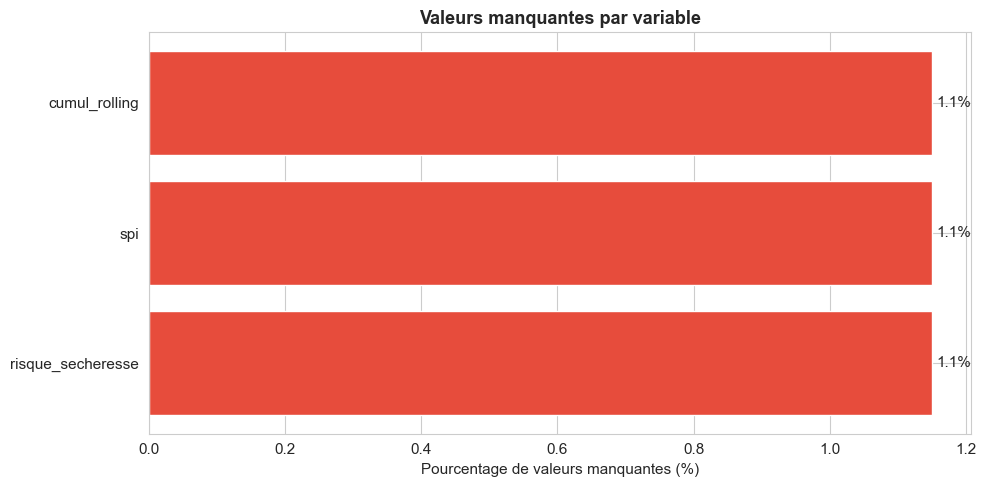

Explication : Les NaN au debut sont normaux — le SPI necessite 3 mois de donnees.


In [7]:
# Calcul des valeurs manquantes
nan_counts = df.isnull().sum()
nan_pct    = (nan_counts / len(df) * 100).round(2)

nan_df = pd.DataFrame({
    'Valeurs manquantes': nan_counts,
    'Pourcentage (%)':    nan_pct
}).sort_values('Valeurs manquantes', ascending=False)

print(nan_df)

# Visualisation
fig, ax = plt.subplots(figsize=(10, 5))
cols_avec_nan = nan_df[nan_df['Valeurs manquantes'] > 0]
if len(cols_avec_nan) > 0:
    bars = ax.barh(cols_avec_nan.index, cols_avec_nan['Pourcentage (%)'], color='#e74c3c')
    ax.bar_label(bars, fmt='%.1f%%', padding=3)
    ax.set_xlabel('Pourcentage de valeurs manquantes (%)')
    ax.set_title('Valeurs manquantes par variable')
else:
    ax.text(0.5, 0.5, 'Aucune valeur manquante !', ha='center', va='center',
            fontsize=14, color='green', transform=ax.transAxes)
    ax.set_title('Analyse des valeurs manquantes')
plt.tight_layout()
plt.savefig('../data/nan_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('Explication : Les NaN au debut sont normaux — le SPI necessite 3 mois de donnees.')

---
## 5. 📈 Distribution des variables numériques

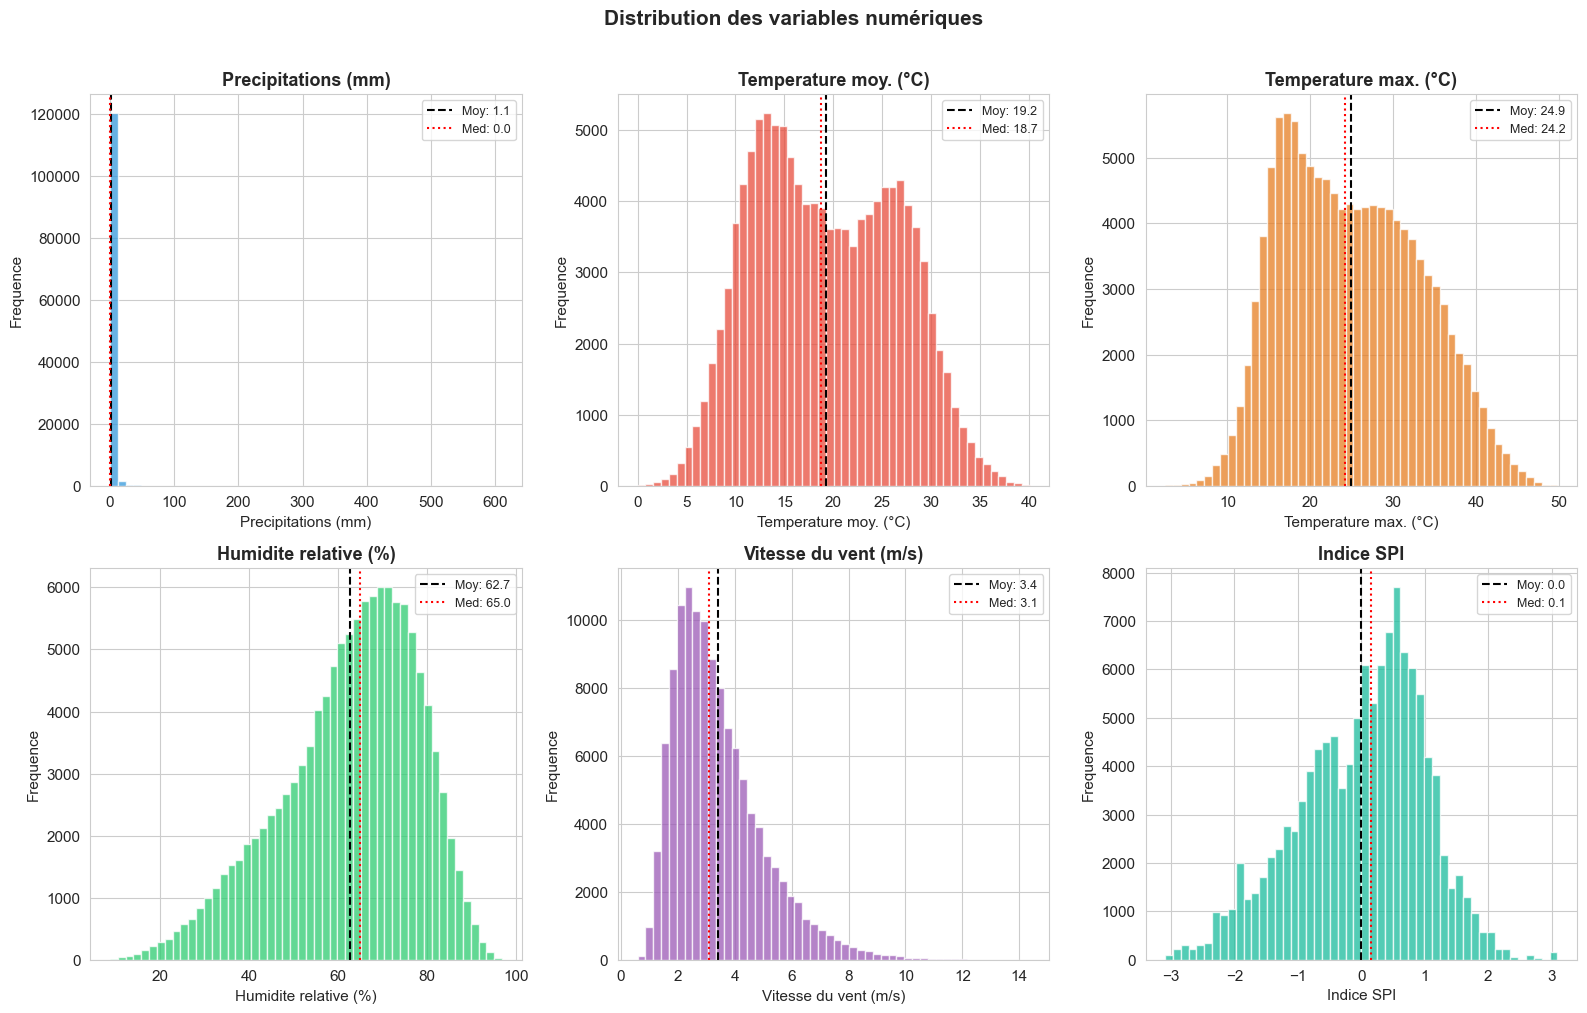

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

vars_plot = [
    ('precipitations_mm', 'Precipitations (mm)',    '#3498db'),
    ('temperature_moy',   'Temperature moy. (°C)',  '#e74c3c'),
    ('temperature_max',   'Temperature max. (°C)',  '#e67e22'),
    ('humidite_pct',      'Humidite relative (%)',  '#2ecc71'),
    ('vent_ms',           'Vitesse du vent (m/s)',  '#9b59b6'),
    ('spi',               'Indice SPI',             '#1abc9c'),
]

for ax, (col, label, color) in zip(axes, vars_plot):
    data = df[col].dropna()
    ax.hist(data, bins=50, color=color, alpha=0.75, edgecolor='white')
    ax.axvline(data.mean(),   color='black', linestyle='--', linewidth=1.5, label=f'Moy: {data.mean():.1f}')
    ax.axvline(data.median(), color='red',   linestyle=':',  linewidth=1.5, label=f'Med: {data.median():.1f}')
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel('Frequence')
    ax.legend(fontsize=9)

plt.suptitle('Distribution des variables numériques', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../data/distributions.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 6. 🎯 Distribution de la variable cible (risque_secheresse)

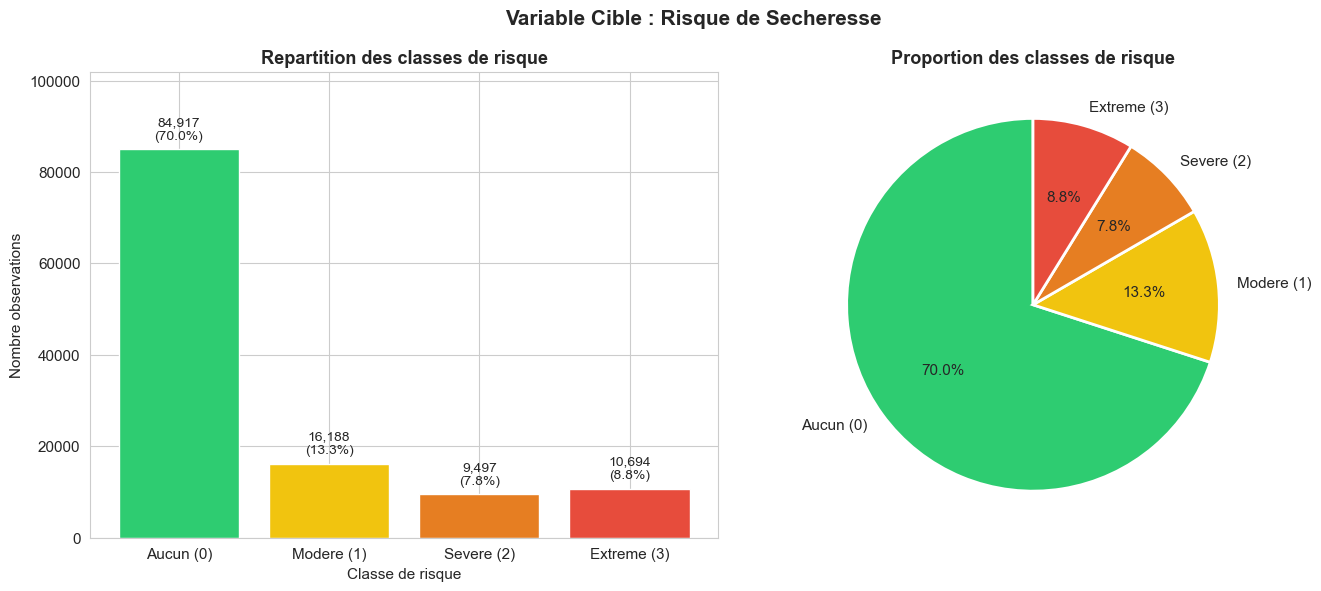

Observation : Desequilibre de classes detecte — Classe 0 majoritaire (normal).
Solution prevue dans le preprocessing : class_weight="balanced" ou SMOTE.


In [9]:
# Supprimer les NaN de la variable cible pour l'analyse
df_cible = df.dropna(subset=['risque_secheresse']).copy()
df_cible['risque_secheresse'] = df_cible['risque_secheresse'].astype(int)

labels  = {0: 'Aucun (0)', 1: 'Modere (1)', 2: 'Severe (2)', 3: 'Extreme (3)'}
colors  = ['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c']
counts  = df_cible['risque_secheresse'].value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Barplot
bars = ax1.bar([labels[i] for i in counts.index], counts.values, color=colors)
ax1.bar_label(bars, labels=[f'{v:,}\n({v/len(df_cible)*100:.1f}%)' for v in counts.values],
              padding=5, fontsize=10)
ax1.set_title('Repartition des classes de risque')
ax1.set_ylabel('Nombre observations')
ax1.set_xlabel('Classe de risque')
ax1.set_ylim(0, counts.max() * 1.2)

# Pie chart
ax2.pie(counts.values,
        labels=[labels[i] for i in counts.index],
        colors=colors,
        autopct='%1.1f%%',
        startangle=90,
        wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax2.set_title('Proportion des classes de risque')

plt.suptitle('Variable Cible : Risque de Secheresse', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print('Observation : Desequilibre de classes detecte — Classe 0 majoritaire (normal).')
print('Solution prevue dans le preprocessing : class_weight="balanced" ou SMOTE.')

---
## 7. 🗺️ Analyse par région géographique

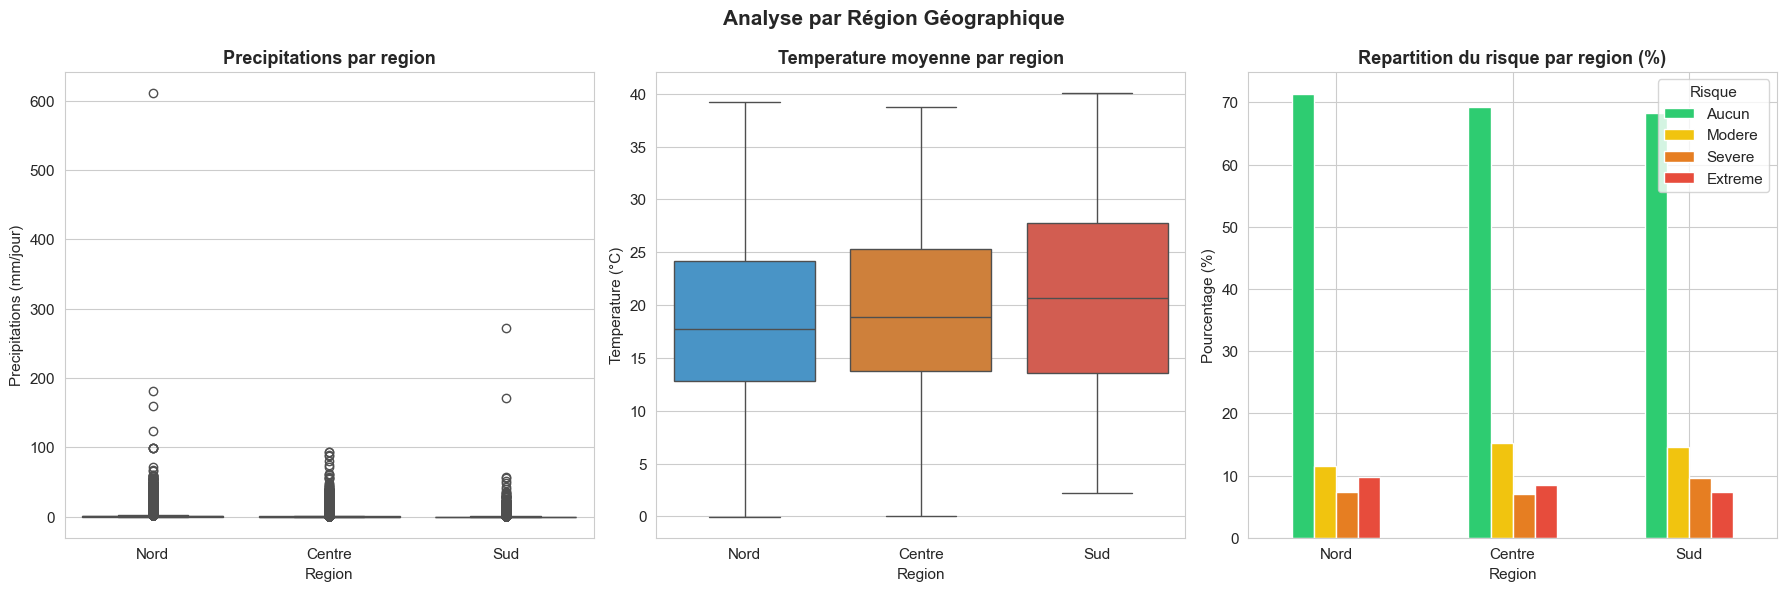

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Precipitations par region
sns.boxplot(data=df, x='region', y='precipitations_mm',
            order=['Nord','Centre','Sud'],
            palette=['#3498db','#e67e22','#e74c3c'], ax=axes[0])
axes[0].set_title('Precipitations par region')
axes[0].set_ylabel('Precipitations (mm/jour)')
axes[0].set_xlabel('Region')

# Temperature par region
sns.boxplot(data=df, x='region', y='temperature_moy',
            order=['Nord','Centre','Sud'],
            palette=['#3498db','#e67e22','#e74c3c'], ax=axes[1])
axes[1].set_title('Temperature moyenne par region')
axes[1].set_ylabel('Temperature (°C)')
axes[1].set_xlabel('Region')

# Risque par region
risque_region = df_cible.groupby(['region','risque_secheresse']).size().unstack(fill_value=0)
risque_region_pct = risque_region.div(risque_region.sum(axis=1), axis=0) * 100
risque_region_pct.loc[['Nord','Centre','Sud']].plot(
    kind='bar', ax=axes[2],
    color=['#2ecc71','#f1c40f','#e67e22','#e74c3c'],
    edgecolor='white'
)
axes[2].set_title('Repartition du risque par region (%)')
axes[2].set_ylabel('Pourcentage (%)')
axes[2].set_xlabel('Region')
axes[2].tick_params(axis='x', rotation=0)
axes[2].legend(['Aucun','Modere','Severe','Extreme'], title='Risque')

plt.suptitle('Analyse par Région Géographique', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/analyse_region.png', dpi=150, bbox_inches='tight')
plt.show()

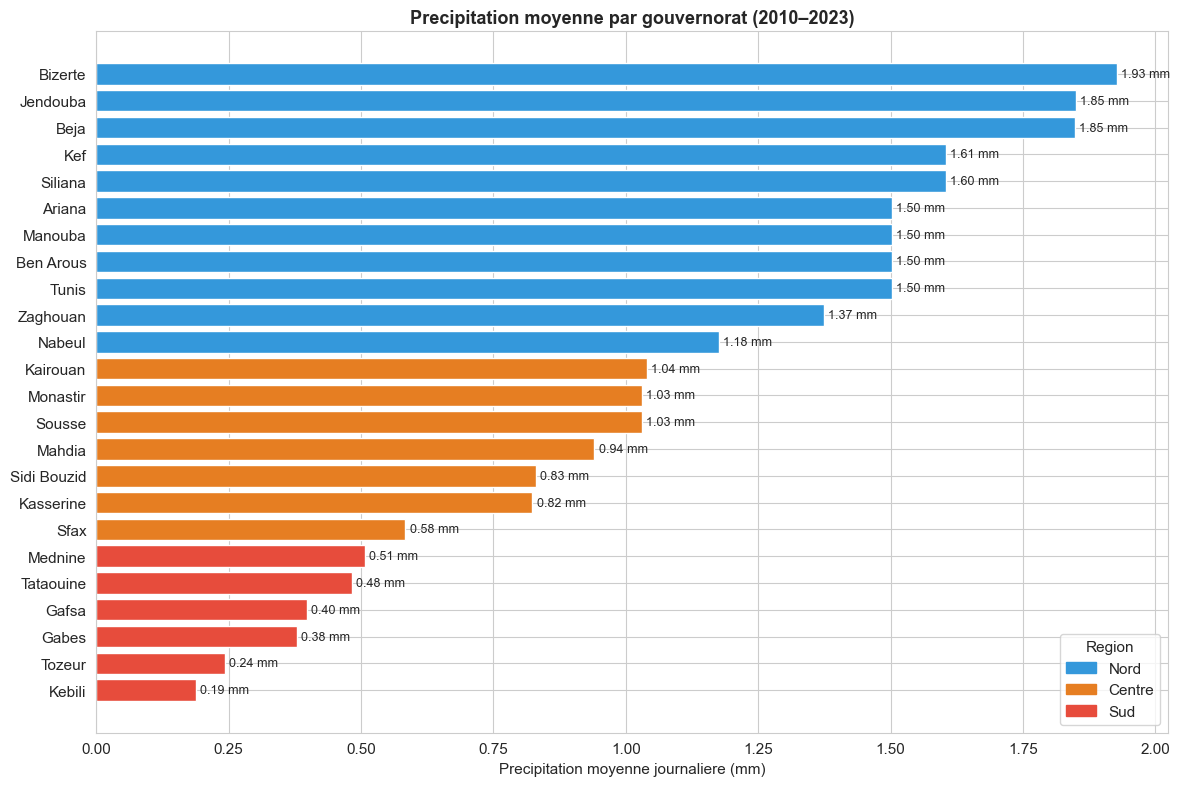

In [11]:
# Precipitations moyennes par gouvernorat
moy_gouv = df.groupby('gouvernorat')['precipitations_mm'].mean().sort_values(ascending=True)

# Associer les couleurs par region
region_map = df.drop_duplicates('gouvernorat').set_index('gouvernorat')['region']
color_map  = {'Nord': '#3498db', 'Centre': '#e67e22', 'Sud': '#e74c3c'}
bar_colors = [color_map[region_map[g]] for g in moy_gouv.index]

fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(moy_gouv.index, moy_gouv.values, color=bar_colors)
ax.bar_label(bars, fmt='%.2f mm', padding=3, fontsize=9)
ax.set_xlabel('Precipitation moyenne journaliere (mm)')
ax.set_title('Precipitation moyenne par gouvernorat (2010–2023)')

# Legende manuelle
from matplotlib.patches import Patch
legend = [Patch(color='#3498db', label='Nord'),
          Patch(color='#e67e22', label='Centre'),
          Patch(color='#e74c3c', label='Sud')]
ax.legend(handles=legend, title='Region')

plt.tight_layout()
plt.savefig('../data/precipitations_gouvernorat.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 8. 📅 Évolution temporelle des précipitations

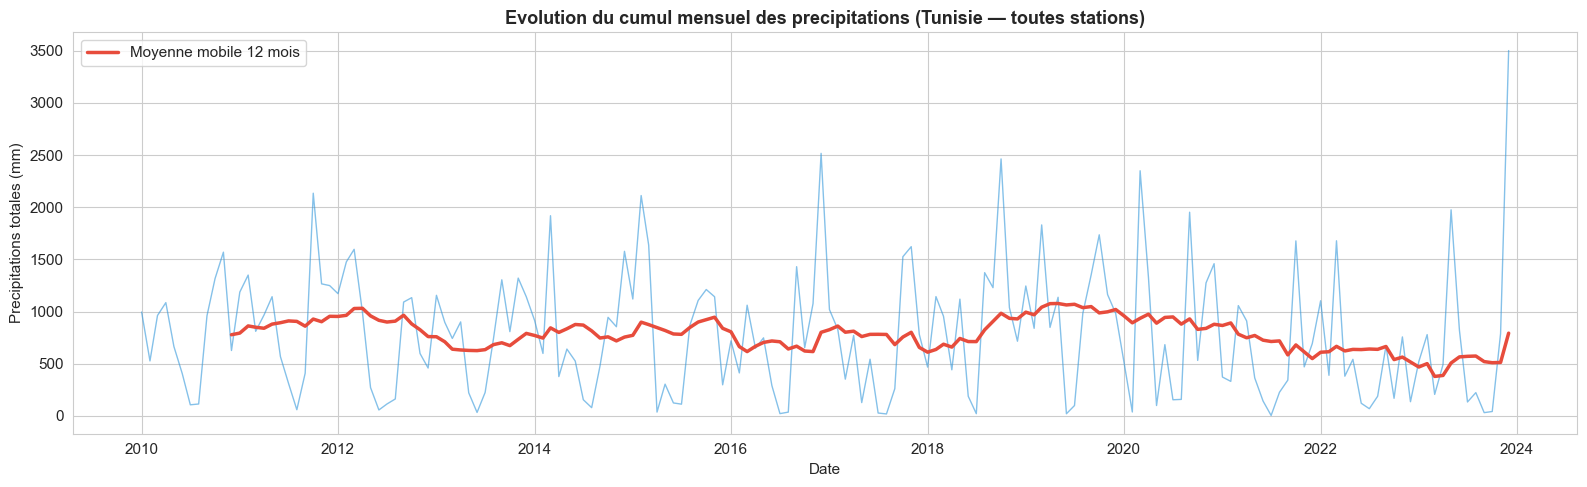

In [12]:
# Cumul mensuel moyen toutes regions
cumul_mensuel = df.groupby('annee_mois')['precipitations_mm'].sum().reset_index()
cumul_mensuel['annee_mois_dt'] = cumul_mensuel['annee_mois'].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(cumul_mensuel['annee_mois_dt'], cumul_mensuel['precipitations_mm'],
        color='#3498db', linewidth=1, alpha=0.6)
# Moyenne mobile 12 mois
cumul_mensuel['rolling_12'] = cumul_mensuel['precipitations_mm'].rolling(12).mean()
ax.plot(cumul_mensuel['annee_mois_dt'], cumul_mensuel['rolling_12'],
        color='#e74c3c', linewidth=2.5, label='Moyenne mobile 12 mois')
ax.set_title('Evolution du cumul mensuel des precipitations (Tunisie — toutes stations)')
ax.set_xlabel('Date')
ax.set_ylabel('Precipitations totales (mm)')
ax.legend()
plt.tight_layout()
plt.savefig('../data/evolution_temporelle.png', dpi=150, bbox_inches='tight')
plt.show()

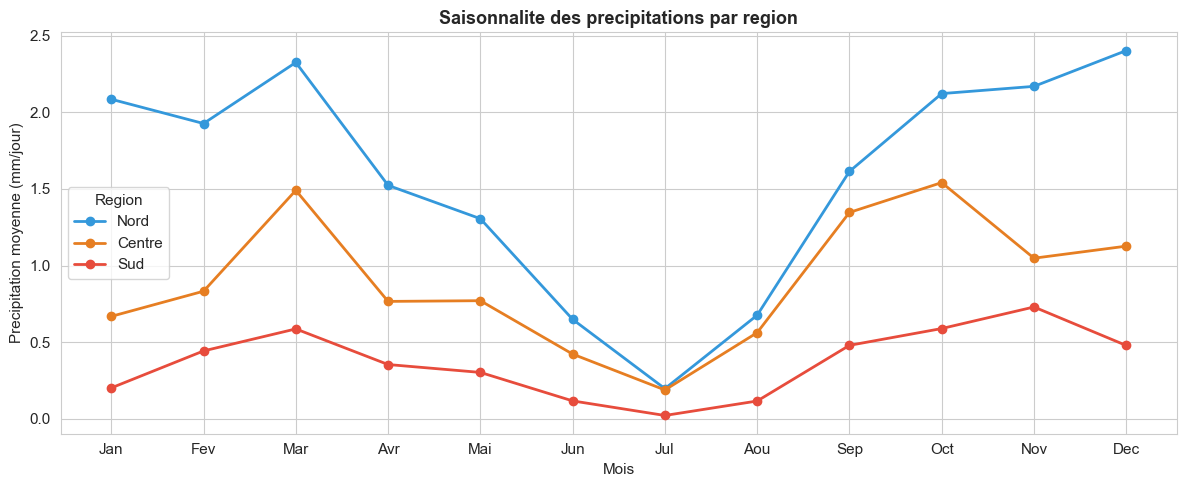

In [13]:
# Saisonnalite : precipitations moyennes par mois
saisonnalite = df.groupby(['mois','region'])['precipitations_mm'].mean().unstack()

mois_labels = ['Jan','Fev','Mar','Avr','Mai','Jun','Jul','Aou','Sep','Oct','Nov','Dec']

fig, ax = plt.subplots(figsize=(12, 5))
for region, color in zip(['Nord','Centre','Sud'], ['#3498db','#e67e22','#e74c3c']):
    if region in saisonnalite.columns:
        ax.plot(range(1,13), saisonnalite[region].values,
                marker='o', color=color, linewidth=2, label=region)

ax.set_xticks(range(1,13))
ax.set_xticklabels(mois_labels)
ax.set_title('Saisonnalite des precipitations par region')
ax.set_xlabel('Mois')
ax.set_ylabel('Precipitation moyenne (mm/jour)')
ax.legend(title='Region')
plt.tight_layout()
plt.savefig('../data/saisonnalite.png', dpi=150, bbox_inches='tight')
plt.show()

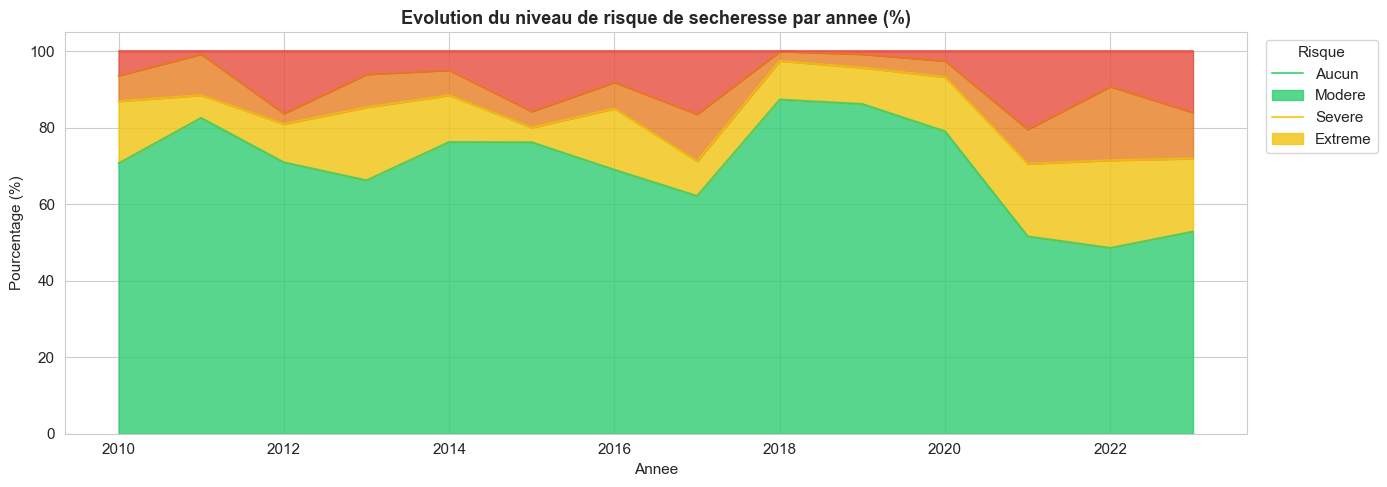

In [14]:
# Evolution du risque par annee
risque_annuel = df_cible.groupby(['annee','risque_secheresse']).size().unstack(fill_value=0)
risque_annuel_pct = risque_annuel.div(risque_annuel.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(14, 5))
risque_annuel_pct.plot(
    kind='area', ax=ax, stacked=True,
    color=['#2ecc71','#f1c40f','#e67e22','#e74c3c'],
    alpha=0.8
)
ax.set_title('Evolution du niveau de risque de secheresse par annee (%)')
ax.set_xlabel('Annee')
ax.set_ylabel('Pourcentage (%)')
ax.legend(['Aucun','Modere','Severe','Extreme'], title='Risque', bbox_to_anchor=(1.01,1))
plt.tight_layout()
plt.savefig('../data/evolution_risque.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 9. 🔗 Matrice de corrélation

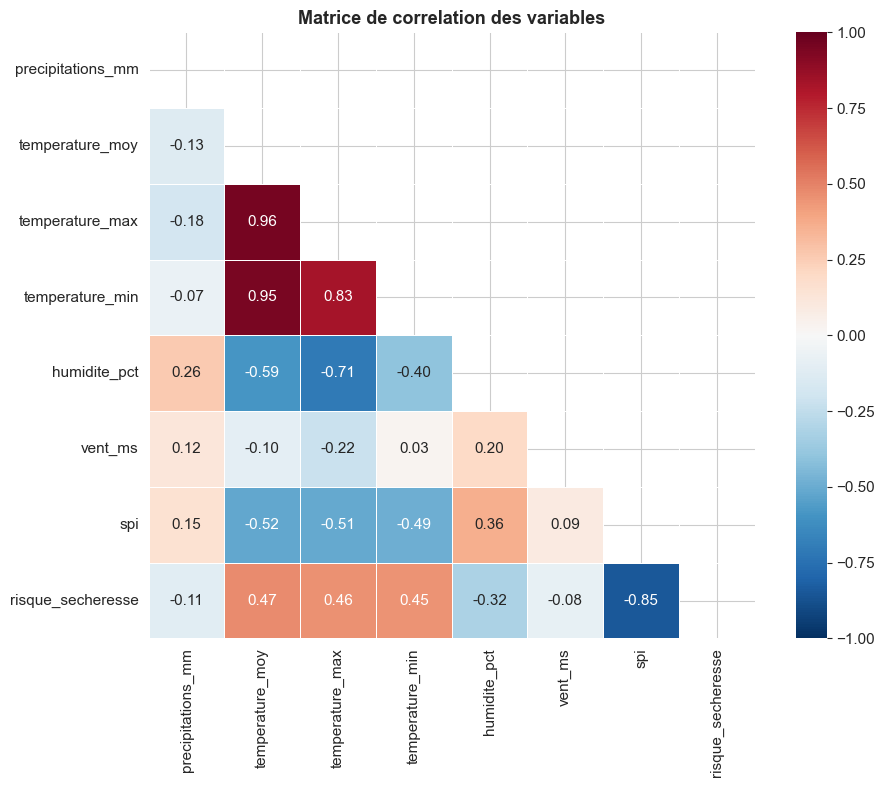

Correlation avec risque_secheresse :
spi                 -0.85
humidite_pct        -0.32
precipitations_mm   -0.11
vent_ms             -0.08
temperature_min      0.45
temperature_max      0.46
temperature_moy      0.47
Name: risque_secheresse, dtype: float64


In [15]:
vars_corr = ['precipitations_mm','temperature_moy','temperature_max',
             'temperature_min','humidite_pct','vent_ms','spi','risque_secheresse']

corr_matrix = df_cible[vars_corr].astype(float).corr().round(2)

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix,
            mask=mask,
            annot=True, fmt='.2f',
            cmap='RdBu_r',
            vmin=-1, vmax=1,
            linewidths=0.5,
            ax=ax,
            square=True)
ax.set_title('Matrice de correlation des variables')
plt.tight_layout()
plt.savefig('../data/correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# Variables les plus correlees avec la cible
print('Correlation avec risque_secheresse :')
print(corr_matrix['risque_secheresse'].drop('risque_secheresse').sort_values())

---
## 10. 📦 Détection des outliers (Boxplots)

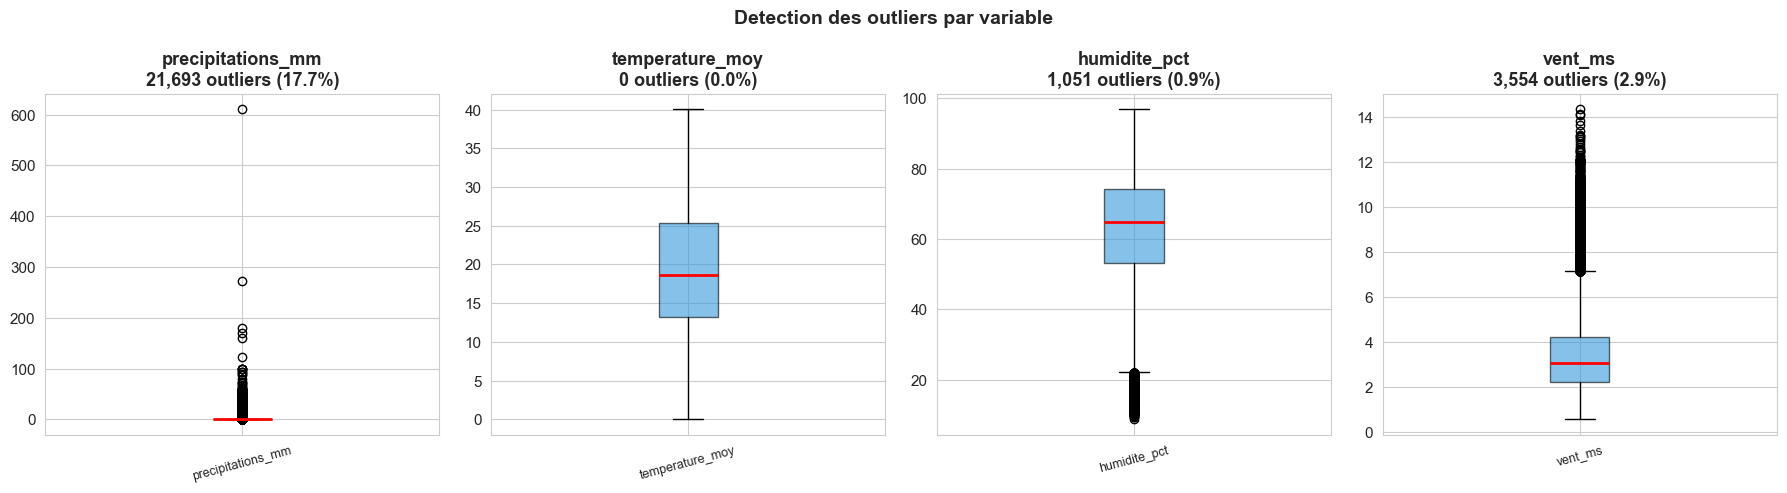

In [16]:
vars_outliers = ['precipitations_mm','temperature_moy','humidite_pct','vent_ms']

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, col in zip(axes, vars_outliers):
    data = df[col].dropna()
    Q1, Q3 = data.quantile(0.25), data.quantile(0.75)
    IQR    = Q3 - Q1
    n_out  = ((data < Q1 - 1.5*IQR) | (data > Q3 + 1.5*IQR)).sum()
    pct    = n_out / len(data) * 100

    ax.boxplot(data, patch_artist=True,
               boxprops=dict(facecolor='#3498db', alpha=0.6),
               medianprops=dict(color='red', linewidth=2))
    ax.set_title(f'{col}\n{n_out:,} outliers ({pct:.1f}%)')
    ax.set_xticklabels([col], rotation=15, fontsize=9)

plt.suptitle('Detection des outliers par variable', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/outliers.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 11. ✅ Conclusions de l'EDA

In [17]:
print('=' * 60)
print('  SYNTHESE DE L\'ANALYSE EXPLORATOIRE')
print('=' * 60)

print(f"""
DATASET
  - {len(df):,} observations | 24 gouvernorats | 2010-2023
  - {len(df.columns)} variables disponibles

VALEURS MANQUANTES
  - SPI et risque : NaN les 3 premiers mois (normal)
  - Solution : supprimer ces lignes avant modelisation

VARIABLE CIBLE (risque_secheresse)
  - Classe 0 (Aucun)   : {(df_cible['risque_secheresse']==0).sum():,} obs ({(df_cible['risque_secheresse']==0).mean()*100:.1f}%)
  - Classe 1 (Modere)  : {(df_cible['risque_secheresse']==1).sum():,} obs ({(df_cible['risque_secheresse']==1).mean()*100:.1f}%)
  - Classe 2 (Severe)  : {(df_cible['risque_secheresse']==2).sum():,} obs ({(df_cible['risque_secheresse']==2).mean()*100:.1f}%)
  - Classe 3 (Extreme) : {(df_cible['risque_secheresse']==3).sum():,} obs ({(df_cible['risque_secheresse']==3).mean()*100:.1f}%)
  => Desequilibre detecte : appliquer class_weight='balanced'

OBSERVATIONS CLES
  - Le Nord recoit plus de precipitations que le Centre et le Sud
  - La saisonnalite est marquee : hiver humide, ete sec
  - SPI et precipitations sont fortement correlees a la cible
  - Temperature negativement correlee avec les precipitations
  - Des outliers sur precipitations (pluies intenses) : a traiter

PROCHAINE ETAPE
  → Notebook 02_Modeling.ipynb : Preprocessing + Modelisation
""")
print('=' * 60)

  SYNTHESE DE L'ANALYSE EXPLORATOIRE

DATASET
  - 122,712 observations | 24 gouvernorats | 2010-2023
  - 19 variables disponibles

VALEURS MANQUANTES
  - SPI et risque : NaN les 3 premiers mois (normal)
  - Solution : supprimer ces lignes avant modelisation

VARIABLE CIBLE (risque_secheresse)
  - Classe 0 (Aucun)   : 84,917 obs (70.0%)
  - Classe 1 (Modere)  : 16,188 obs (13.3%)
  - Classe 2 (Severe)  : 9,497 obs (7.8%)
  - Classe 3 (Extreme) : 10,694 obs (8.8%)
  => Desequilibre detecte : appliquer class_weight='balanced'

OBSERVATIONS CLES
  - Le Nord recoit plus de precipitations que le Centre et le Sud
  - La saisonnalite est marquee : hiver humide, ete sec
  - SPI et precipitations sont fortement correlees a la cible
  - Temperature negativement correlee avec les precipitations
  - Des outliers sur precipitations (pluies intenses) : a traiter

PROCHAINE ETAPE
  → Notebook 02_Modeling.ipynb : Preprocessing + Modelisation

